# Lab 7 — HMM Noun-Phrase Chunking: Forward Algorithm + Viterbi Decoding

Task: tag each word of a sentence as **B-NP** (beginning of a noun phrase),
**I-NP** (inside a noun phrase), or **O** (outside any noun phrase), using a
first-order Hidden Markov Model trained on `Data/train_NP.txt` and
evaluated on `Data/test_NP.txt` (standard CoNLL-2000-style chunking data,
tab-separated `word<TAB>tag`, blank line between sentences).

1. **Forward algorithm** — compute P(sentence) under the HMM for every test
   sentence.
2. **Viterbi decoding** — predict the most likely B-NP/I-NP/O tag sequence
   for every test sentence, evaluated with
   [`seqeval`](https://pypi.org/project/seqeval/).

Zero counts (unseen word/tag or tag/tag pairs) are handled with **Add-K
smoothing** throughout — transition, emission, and initial-state
probabilities all use the same smoothed estimator.


## 0. Setup

In [1]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "seqeval", "pandas", "matplotlib", "numpy"])


CompletedProcess(args=['/home/deeraj/miniconda3/bin/python3.13', '-m', 'pip', 'install', '-q', 'seqeval', 'pandas', 'matplotlib', 'numpy'], returncode=0)

In [2]:
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from seqeval.metrics import classification_report, f1_score

DATA_DIR = "Data"
OUT_DIR = "data"
import os
os.makedirs(OUT_DIR, exist_ok=True)


## 1. Load the data

Each sentence is a list of `(word, tag)` pairs; sentences are separated by
blank lines in the source files.

In [3]:
def load_conll(path):
    sentences, current = [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if line.strip() == "":
                if current:
                    sentences.append(current)
                    current = []
            else:
                word, tag = line.split("\t")
                current.append((word, tag))
    if current:
        sentences.append(current)
    return sentences


train = load_conll(f"{DATA_DIR}/train_NP.txt")
test = load_conll(f"{DATA_DIR}/test_NP.txt")

print(f"train sentences: {len(train)}   test sentences: {len(test)}")
print(f"train tokens: {sum(len(s) for s in train)}   test tokens: {sum(len(s) for s in test)}")
print("example sentence:", train[0][:8], "...")

tag_dist = Counter(t for sent in train for _, t in sent)
pd.Series(tag_dist, name="count").to_frame().T


train sentences: 823   test sentences: 77
train tokens: 19172   test tokens: 1896
example sentence: [('Rockwell', 'B-NP'), ('International', 'I-NP'), ('Corp.', 'I-NP'), ("'s", 'B-NP'), ('Tulsa', 'I-NP'), ('unit', 'I-NP'), ('said', 'O'), ('it', 'B-NP')] ...


,B-NP,I-NP,O
count,5051,5727,8394


## 2. HMM parameters with Add-K smoothing

Three sets of parameters are estimated from the training data:

- **Initial probabilities** `π(s) = P(tag_1 = s)` — how often a sentence
  starts with tag `s`.
- **Transition probabilities** `A(s' | s) = P(tag_i = s' | tag_{i-1} = s)`.
- **Emission probabilities** `B(w | s) = P(word_i = w | tag_i = s)`.

All three are **Add-K smoothed**: every count gets `+k` before
normalizing, so a word/tag or tag/tag pair never seen in training still
gets a small nonzero probability instead of killing the whole sequence
probability. `V` below is the training vocabulary size, used to normalize
the emission distribution; a test word that never appeared in training at
all is scored with an emission count of exactly `0 + k` under every tag
(the same Add-K treatment as an in-vocabulary zero count).

In [4]:
STATES = ["O", "B-NP", "I-NP"]
STATE_IDX = {s: i for i, s in enumerate(STATES)}
N_STATES = len(STATES)

vocab = set()
tag_count = Counter()
emit_count = Counter()
trans_count = Counter()
init_count = Counter()

for sent in train:
    words = [w for w, _ in sent]
    tags = [t for _, t in sent]
    vocab.update(words)
    init_count[tags[0]] += 1
    for i, (w, t) in enumerate(sent):
        tag_count[t] += 1
        emit_count[(w, t)] += 1
        if i > 0:
            trans_count[(tags[i - 1], tags[i])] += 1

V = len(vocab)
N_SENT = len(train)
print(f"vocabulary size V = {V}")


class HMM:
    def __init__(self, k):
        self.k = k

    def init_logprob(self, tag):
        return math.log((init_count.get(tag, 0) + self.k) / (N_SENT + self.k * N_STATES))

    def trans_logprob(self, prev, cur):
        denom = sum(trans_count.get((prev, s), 0) for s in STATES) + self.k * N_STATES
        return math.log((trans_count.get((prev, cur), 0) + self.k) / denom)

    def emit_logprob(self, word, tag):
        return math.log((emit_count.get((word, tag), 0) + self.k) / (tag_count[tag] + self.k * V))


vocabulary size V = 4570


## 3. Forward algorithm — P(sentence)

Standard forward recursion in **log-space** (log-sum-exp for the
summation step), since even a 20-word sentence's raw probability
underflows a double-precision float well before the end of the sentence.

`alpha[t][s] = log P(obs_1..t, tag_t = s)`, and
`log P(sentence) = logsumexp_s(alpha[T-1][s])`.

In [5]:
def logsumexp(values):
    m = max(values)
    if m == -math.inf:
        return -math.inf
    return m + math.log(sum(math.exp(v - m) for v in values))


def forward(words, hmm):
    T = len(words)
    alpha = [[0.0] * N_STATES for _ in range(T)]
    for s in range(N_STATES):
        alpha[0][s] = hmm.init_logprob(STATES[s]) + hmm.emit_logprob(words[0], STATES[s])
    for t in range(1, T):
        for s in range(N_STATES):
            incoming = [alpha[t - 1][sp] + hmm.trans_logprob(STATES[sp], STATES[s]) for sp in range(N_STATES)]
            alpha[t][s] = logsumexp(incoming) + hmm.emit_logprob(words[t], STATES[s])
    return logsumexp(alpha[T - 1]), alpha


In [6]:
hmm_k1 = HMM(k=1.0)

rows = []
for sent in test:
    words = [w for w, _ in sent]
    logp, _ = forward(words, hmm_k1)
    rows.append({"n_tokens": len(words), "log_P(sentence)": logp,
                 "log_P_per_token": logp / len(words),
                 "sentence": " ".join(words[:8]) + (" ..." if len(words) > 8 else "")})

forward_df = pd.DataFrame(rows)
avg_logprob_per_token = (forward_df["log_P(sentence)"].sum() / forward_df["n_tokens"].sum())
perplexity = math.exp(-avg_logprob_per_token)
print(f"mean log P(sentence) per test sentence: {forward_df['log_P(sentence)'].mean():.2f}")
print(f"token-normalized perplexity on test set: {perplexity:.2f}")
forward_df.to_csv(f"{OUT_DIR}/forward_logprobs.csv", index=False)
forward_df.head(10)


mean log P(sentence) per test sentence: -170.95
token-normalized perplexity on test set: 1035.39


,n_tokens,log_P(sentence),log_P_per_token,sentence
0,37,-261.819797,-7.076211,Confidence in the pound is widely expected to ...
1,27,-187.415011,-6.941297,Chancellor of the Exchequer Nigel Lawson 's re...
2,29,-212.242009,-7.318690,But analysts reckon underlying support for ste...
3,36,-242.403540,-6.733432,This has increased the risk of the government ...
4,31,-217.350738,-7.011314,`` The risks for sterling of a bad ...
5,36,-251.738738,-6.992743,`` If there is another bad trade number ...
6,39,-271.751384,-6.967984,"Forecasts for the trade figures range widely ,..."
7,25,-177.928850,-7.117154,The August deficit and the # 2.2 billion ...
8,28,-201.785279,-7.206617,"Sanjay Joshi , European economist at Baring Br..."
9,24,-169.651612,-7.068817,"At the same time , he remains fairly ..."


## 4. Viterbi decoding — most likely tag sequence

Same log-space recursion as the forward algorithm, but **max** instead of
**sum**, with backpointers to recover the arg-max path.
`delta[t][s] = log P(best path ending in tag s at time t, obs_1..t)`.

In [7]:
def viterbi(words, hmm):
    T = len(words)
    delta = [[0.0] * N_STATES for _ in range(T)]
    psi = [[0] * N_STATES for _ in range(T)]
    for s in range(N_STATES):
        delta[0][s] = hmm.init_logprob(STATES[s]) + hmm.emit_logprob(words[0], STATES[s])
    for t in range(1, T):
        for s in range(N_STATES):
            best_val, best_prev = -math.inf, 0
            for sp in range(N_STATES):
                val = delta[t - 1][sp] + hmm.trans_logprob(STATES[sp], STATES[s])
                if val > best_val:
                    best_val, best_prev = val, sp
            delta[t][s] = best_val + hmm.emit_logprob(words[t], STATES[s])
            psi[t][s] = best_prev
    last_state = max(range(N_STATES), key=lambda s: delta[T - 1][s])
    path = [last_state]
    for t in range(T - 1, 0, -1):
        path.append(psi[t][path[-1]])
    path.reverse()
    return [STATES[i] for i in path]


In [8]:
example = test[3]
words = [w for w, _ in example]
gold = [t for _, t in example]
pred = viterbi(words, hmm_k1)

pd.DataFrame({"word": words, "gold": gold, "pred": pred,
              "correct": [g == p for g, p in zip(gold, pred)]})


,word,gold,pred,correct
0,This,B-NP,B-NP,True
1,has,O,O,True
2,increased,O,O,True
3,the,B-NP,B-NP,True
4,risk,I-NP,I-NP,True
5,of,O,O,True
6,the,B-NP,B-NP,True
7,government,I-NP,I-NP,True
8,being,O,O,True
9,forced,O,O,True


## 5. Choosing K: a smoothing sweep

Add-K smoothing trades off two failure modes: `k` too large flattens the
emission distribution toward uniform (common words lose their
discriminative power), `k` too small barely smooths zero counts at all
(OOV test words get an almost-arbitrary tag). Sweeping `k` and scoring
Viterbi predictions on the full test set with `seqeval` makes this
trade-off visible rather than just picking `k=1` by convention.

best k = 0.1  (f1 = 0.7102)


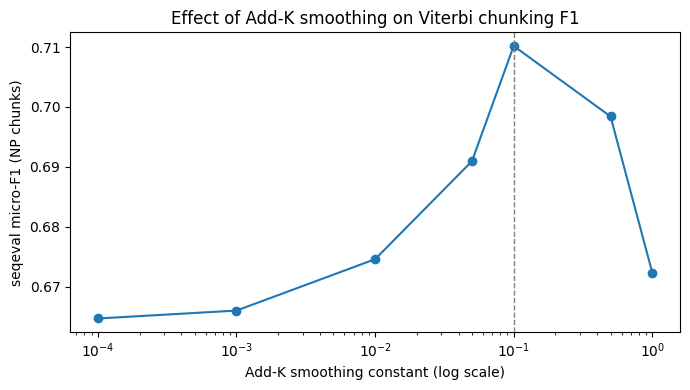

,k,f1
0,1.0000,0.672340
1,0.5000,0.698413
2,0.1000,0.710188
3,0.0500,0.690945
4,0.0100,0.674580
5,0.0010,0.666006
6,0.0001,0.664683


In [9]:
def evaluate(hmm, sentences):
    y_true, y_pred = [], []
    for sent in sentences:
        words = [w for w, _ in sent]
        gold = [t for _, t in sent]
        y_true.append(gold)
        y_pred.append(viterbi(words, hmm))
    return y_true, y_pred


k_values = [1.0, 0.5, 0.1, 0.05, 0.01, 0.001, 0.0001]
sweep_rows = []
for k in k_values:
    hmm_k = HMM(k=k)
    y_true, y_pred = evaluate(hmm_k, test)
    sweep_rows.append({"k": k, "f1": f1_score(y_true, y_pred)})

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(f"{OUT_DIR}/addk_sweep.csv", index=False)
best_k = sweep_df.loc[sweep_df["f1"].idxmax(), "k"]
print(f"best k = {best_k}  (f1 = {sweep_df['f1'].max():.4f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep_df["k"], sweep_df["f1"], marker="o")
ax.set_xscale("log")
ax.set_xlabel("Add-K smoothing constant (log scale)")
ax.set_ylabel("seqeval micro-F1 (NP chunks)")
ax.set_title("Effect of Add-K smoothing on Viterbi chunking F1")
ax.axvline(best_k, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/addk_sweep.png", dpi=150)
plt.show()
sweep_df


## 6. Final evaluation at the best K

Full `seqeval` classification report (precision/recall/F1 at the
**NP-chunk** level — a predicted chunk counts as correct only if its span
*and* its B-NP/I-NP boundary exactly match the gold chunk, which is
stricter than token-level accuracy).

In [10]:
best_hmm = HMM(k=best_k)
y_true, y_pred = evaluate(best_hmm, test)

token_acc = np.mean([g == p for gs, ps in zip(y_true, y_pred) for g, p in zip(gs, ps)])
print(f"k = {best_k}")
print(f"token-level accuracy (B-NP/I-NP/O, all 3 tags): {token_acc:.4f}\n")
report_str = classification_report(y_true, y_pred, digits=4)
print("seqeval chunk-level report (NP spans only):")
print(report_str)

with open(f"{OUT_DIR}/final_report.txt", "w") as f:
    f.write(f"best_k={best_k}\ntoken_accuracy={token_acc:.4f}\n\n{report_str}")


k = 0.1
token-level accuracy (B-NP/I-NP/O, all 3 tags): 0.8613

seqeval chunk-level report (NP spans only):
              precision    recall  f1-score   support

          NP     0.6698    0.7558    0.7102       475

   micro avg     0.6698    0.7558    0.7102       475
   macro avg     0.6698    0.7558    0.7102       475
weighted avg     0.6698    0.7558    0.7102       475



## 7. Discussion

- **Forward vs. Viterbi** compute different quantities over the same
  trellis: forward **sums** over every possible tag path to get the total
  probability of the observed words (§3); Viterbi **maximizes** over paths
  to find the single best explanation (§4). Both need log-space arithmetic
  — the raw per-sentence probabilities underflow double precision well
  before 20 tokens.
- **Add-K smoothing is not a minor detail here.** The sweep in §5 shows
  `k=1` (plain Laplace) is a poor choice for this emission distribution —
  the training vocabulary is large relative to per-tag counts, so `+1` to
  every count flattens emissions enough to visibly hurt chunk F1 compared
  to a smaller `k`. Too small a `k` (`1e-4`) underperforms too, since it
  barely smooths the zero counts that out-of-vocabulary test words rely
  on. The sweet spot sits in between.
- **Chunk-level F1 (seqeval) is stricter than token accuracy** because it
  requires the whole NP span's boundaries to match, not just individual
  B-NP/I-NP/O labels — a single misplaced boundary tag can cost an entire
  chunk credit even when most tokens in the sentence are tagged correctly.
